### Kaffeerunde – Lösung Schritt für Schritt

*31. Bundeswettbewerb Informatik (2012), 1. Runde, Aufgabe 5*

Die Inhaberin der Firma Nash GmbH wünscht sich glückliche Mitarbeiter und möchte ihnen fürderhin kostenlos Kaffee anbieten. Hierzu wird Kaffee zur Verfügung gestellt sowie eine Kaffeemaschine mit einer Kanne. Die Mitarbeiter müssen die Maschine selbst bedienen (nach einer Einführungszeit von zehn Tagen, in denen ein Assistent der Inhaberin immer für eine volle Kanne sorgt). Abends wird die Kanne stets entleert.

Die Kanne fasst zehn Tassen und es gibt 15 Mitarbeiter. Jeder Mitarbeiter möchte gern drei Tassen täglich trinken, und zwar je eine vormittags (8–10 Uhr), mittags (12–14 Uhr) und nachmittags (15–17 Uhr). In jedem dieser zweistündigen Intervalle erscheinen die Kaffeetrinker in einer zufälligen Reihenfolge in der Kaffeeküche. Sie verhalten sich dann so:

Falls sich noch Kaffee in der Kanne befindet, nehmen sie sich eine Tasse daraus und gehen wieder. Ist die Kanne aber leer, dann hängt ihr weiteres Verhalten davon ab, ob sie glücklich sind. Falls ja, kochen sie eine neue volle Kanne und nehmen sich davon selbst eine Tasse. Sind sie aber nicht glücklich, dann haben sie keine Lust, für andere Kaffee mitzukochen, und gehen unverrichteter Dinge wieder weg.

Ob eine Person an einem bestimmten Tag glücklich ist, entscheidet sich direkt morgens nach dem Aufstehen und hängt davon ab, wie oft sie in den letzten zehn Tagen selbst Kaffee kochte und wie viele Tassen Kaffee sie in diesem Zeitraum trank. Die genaue Definition lautet: Falls eine Person in den letzten zehn Tagen n Tassen trank und m-mal Kaffee kochte, dann ist sie genau dann glücklich, wenn n ≥ 10 und m/n < a ist, wobei a ein persönlicher Schwellenwert ist.

#### Aufgabe 5

Schreibe ein Programm, das die Kaffeetrinker simuliert, wobei a der Einfachheit halber für alle identisch sein möge. Wie viele Tassen trinkt ein Mitarbeiter täglich im Durchschnitt auf lange Sicht, abhängig von verschiedenen Schwellenwerten a? Ist das Ergebnis so, wie du es erwartetest?

**Zu den Daten:** Beispieldaten gibt es zu dieser Aufgabe nicht. Die Aufgabe verlangt eine Simulation mit Zufall; wir untersuchen verschiedene Schwellenwerte `a` selbst.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Simulation:** Wir bauen den Ablauf Schritt für Schritt nach (Tag für Tag, Tageszeit für Tageszeit, Mitarbeiter für Mitarbeiter) und messen, was dabei herauskommt. Das ist der Weg, wenn eine exakte Rechnung zu schwierig ist.
- **Zustand festlegen:** Man überlegt, was man sich merken muss, damit der nächste Schritt berechnet werden kann: den Füllstand der Kanne und für jeden Mitarbeiter, wie viele Tassen er getrunken und wie oft er gekocht hat, und zwar **je Tag der letzten zehn Tage**.
- **Gleitendes Fenster (Warteschlange):** Jeden Abend kommt der heutige Tag hinten dazu und der älteste Tag vorne fällt weg. Dafür reicht eine Liste mit `append` und `pop(0)`.
- **Zufall und Wiederholung:** Ein einzelner Lauf schwankt. Man simuliert lange (viele Tage) und mittelt. Die ersten Tage, in denen noch der Startzustand wirkt, verfälschen sonst das Ergebnis.
- **Erwartung vor dem Rechnen:** Man schätzt vorher ab, was herauskommen sollte, und vergleicht dann.

**Nützliche Funktionen und Bibliotheken**
- `random.shuffle(liste)`: mischt eine Liste zufällig (damit erscheinen die Mitarbeiter in zufälliger Reihenfolge).
- `random.seed(zahl)`: legt den Zufallsgenerator fest, damit ein Lauf wiederholbar ist.
- `sum(liste)`, `list.pop(0)`, `list.append(x)`.
- `matplotlib.pyplot` (`plot`) für die Kurve „Tassen pro Tag“ in Abhängigkeit von `a`.

## Die Idee in Worten

**Was die Aufgabe offen lässt, legen wir so fest** (es entspricht dem Aufgabentext und den Lösungshinweisen):
- Die Kanne wird **abends geleert**, morgens ist sie also leer. Zwischen den Tageszeiten bleibt der Kaffee in der Kanne: Was vormittags übrig ist, steht mittags noch da, und was mittags übrig ist, nachmittags.
- Wer kocht, füllt eine volle Kanne (10 Tassen) und nimmt sich davon selbst eine Tasse. Es bleiben also **9 Tassen** in der Kanne.
- Ob jemand glücklich ist, wird **einmal am Morgen** festgelegt, mit den Zahlen der letzten zehn Tage (`n` Tassen, `m` Mal gekocht). (Die Hinweise schieben das Fenster dagegen Tageszeit für Tageszeit weiter und prüfen erst beim Kochen. Das ist ein kleiner Unterschied; wir halten uns an den Aufgabentext.)
- **Startphase:** Die ersten zehn Tage sorgt ein Assistent für eine volle Kanne. Jeder trinkt dann an jedem Tag 3 Tassen und kocht nie. Das Zehn-Tage-Fenster eines jeden Mitarbeiters beginnt also mit `n = 30`, `m = 0`. Gemessen wird erst **danach**.

**Der Ablauf.** Für jeden Tag:
1. Morgens für jeden Mitarbeiter feststellen: glücklich oder nicht (`n ≥ 10` und `m/n < a`).
2. Dreimal (vormittags, mittags, nachmittags): Mitarbeiter in zufälliger Reihenfolge durchgehen. Ist Kaffee in der Kanne, trinkt er. Sonst kocht er, wenn er glücklich ist (und trinkt), und geht sonst leer aus.
3. Abends Kanne leeren, für jeden Mitarbeiter die Tassen und Koch-Vorgänge dieses Tages ins Fenster schreiben und den ältesten Tag entfernen.

**Das Ergebnis:** Die Zahl der getrunkenen Tassen geteilt durch (Mitarbeiter · Tage) ist der Durchschnitt pro Mitarbeiter und Tag. Das machen wir für viele Werte von `a`.

**Was wir erwarten.** Nehmen wir an, jeder trinkt im Schnitt `C` Tassen pro Tag. In zehn Tagen trinkt er `10·C` Tassen. Insgesamt werden in den zehn Tagen `15·10·C` Tassen getrunken. Eine Kanne liefert zehn Tassen, also braucht man `15·C` Kannen, das sind im Schnitt `C` Kannen pro Mitarbeiter. Dann ist `m/n = C/(10·C) = 1/10`, unabhängig von `C`. Wir erwarten also eine **Sprungfunktion**: Für `a` über `1/10` trinkt jeder 3 Tassen, für `a` darunter bricht der Kaffeekonsum zusammen (irgendwann ist `n < 10` für alle). Ob es wirklich so kommt, zeigt die Simulation.

## Schritt 1: Eine Tageszeit

Wir fangen mit dem kleinsten Baustein an. In einer Tageszeit kommen alle Mitarbeiter in zufälliger Reihenfolge. Die Funktion bekommt:
- `glueck`: eine Liste mit `True` oder `False` je Mitarbeiter (glücklich oder nicht),
- `kanne`: wie viele Tassen am Anfang in der Kanne sind,
- `tassen` und `gekocht`: Listen, in die wir für jeden Mitarbeiter hineinzählen (Tassen getrunken, Kannen gekocht an diesem Tag).

Sie gibt zurück, wie viele Tassen am Ende in der Kanne sind.

In [ ]:
import random

ANZAHL = 15         # Mitarbeiter
KANNE = 10          # Tassen pro Kanne

def tageszeit(glueck, kanne, tassen, gekocht):
    reihenfolge = list(range(ANZAHL))
    random.shuffle(reihenfolge)             # zufällige Reihenfolge in der Küche
    for m in reihenfolge:
        if kanne > 0:                       # Kaffee da: Tasse nehmen
            kanne = kanne - 1
            tassen[m] = tassen[m] + 1
        elif glueck[m]:                     # leer, aber glücklich: neue Kanne kochen
            kanne = KANNE - 1               # volle Kanne, eine Tasse trinkt der Koch selbst
            tassen[m] = tassen[m] + 1
            gekocht[m] = gekocht[m] + 1
        # sonst: unglücklich und leere Kanne, der Mitarbeiter geht leer aus
    return kanne

# Test: alle glücklich, Kanne leer. Von 15 Personen: 10 Tassen aus Kanne 1 (der Koch dabei), dann kocht der 11.
# Mitarbeiter eine zweite Kanne, und die restlichen 4 trinken daraus.
test_tassen = [0] * ANZAHL
test_gekocht = [0] * ANZAHL
rest = tageszeit([True] * ANZAHL, 0, test_tassen, test_gekocht)
print('Tassen getrunken:', sum(test_tassen), '| Kannen gekocht:', sum(test_gekocht), '| Rest in der Kanne:', rest)

Tassen getrunken: 15 | Kannen gekocht: 2 | Rest in der Kanne: 5


Alle 15 trinken, es wurden **zwei Kannen** gekocht (20 Tassen), 5 Tassen bleiben übrig. Sind dagegen alle unglücklich und die Kanne leer, bekommt niemand etwas:

In [ ]:
test_tassen = [0] * ANZAHL
test_gekocht = [0] * ANZAHL
rest = tageszeit([False] * ANZAHL, 0, test_tassen, test_gekocht)
print('Tassen getrunken:', sum(test_tassen), '| Kannen gekocht:', sum(test_gekocht), '| Rest in der Kanne:', rest)

Tassen getrunken: 0 | Kannen gekocht: 0 | Rest in der Kanne: 0


## Schritt 2: Die ganze Simulation

Jetzt der Rahmen darum. Für jeden Mitarbeiter führen wir zwei Listen mit je 10 Einträgen: wie viele Tassen er an jedem der letzten zehn Tage getrunken hat und wie oft er an diesem Tag gekocht hat. Zu Beginn (Startphase) steht in der ersten Liste überall `3` und in der zweiten überall `0`.

Die Funktion `simuliere(a, tage)` gibt drei Dinge zurück: die durchschnittlich getrunkenen Tassen je Mitarbeiter und Tag, die durchschnittlich gekochten Kannen je Tag und die Liste der Tassen je Mitarbeiter für jeden einzelnen Tag.

In [ ]:
def simuliere(a, tage):
    fenster_tassen = [[3] * 10 for m in range(ANZAHL)]     # je Mitarbeiter: Tassen der letzten 10 Tage
    fenster_kochen = [[0] * 10 for m in range(ANZAHL)]     # je Mitarbeiter: gekochte Kannen der letzten 10 Tage
    summe_tassen = 0
    summe_kannen = 0
    je_tag = []
    for tag in range(tage):
        # Morgens: wer ist glücklich?
        glueck = []
        for m in range(ANZAHL):
            n = sum(fenster_tassen[m])
            k = sum(fenster_kochen[m])
            glueck.append(n >= 10 and k / n < a)
        # Tagsüber: drei Tageszeiten
        tassen = [0] * ANZAHL
        gekocht = [0] * ANZAHL
        kanne = 0                                           # morgens ist die Kanne leer
        for zeit in range(3):
            kanne = tageszeit(glueck, kanne, tassen, gekocht)
        # Abends: Kanne leeren (nichts zu tun), Fenster weiterschieben
        for m in range(ANZAHL):
            fenster_tassen[m].pop(0)
            fenster_tassen[m].append(tassen[m])
            fenster_kochen[m].pop(0)
            fenster_kochen[m].append(gekocht[m])
        summe_tassen = summe_tassen + sum(tassen)
        summe_kannen = summe_kannen + sum(gekocht)
        je_tag.append(sum(tassen) / ANZAHL)
    return summe_tassen / (ANZAHL * tage), summe_kannen / tage, je_tag

# Zwei Extremfälle: a = 1 (alle immer glücklich) und a = 0 (nie jemand glücklich)
random.seed(1)
print('a = 1:', simuliere(1.0, 100)[:2])
print('a = 0:', simuliere(0.0, 100)[:2])

a = 1: (3.0, 5.0)
a = 0: (0.0, 0.0)


Bei `a = 1` ist jeder glücklich, solange er in den letzten zehn Tagen nicht bei jeder Tasse gekocht hat (das kommt nie vor). Jeder trinkt täglich **3 Tassen**, und es werden **5 Kannen pro Tag** gekocht. Warum 5 und nicht 4,5 (45 Tassen : 10)? Das sehen wir gleich in Schritt 5. Bei `a = 0` ist nie jemand glücklich (`m/n < 0` ist unmöglich), niemand kocht, und nach den zehn Tagen der Startphase gibt es keinen Kaffee mehr.

## Schritt 3: Ein Blick auf einzelne Läufe

Bevor wir die Kurve zeichnen, schauen wir die ersten 40 Tage dreier Läufe an: Wie viele Tassen trinkt ein Mitarbeiter im Durchschnitt an jedem einzelnen Tag?

In [ ]:
for a in [0.05, 0.1, 0.3]:
    random.seed(7)
    verlauf = simuliere(a, 40)[2]
    print('a =', a, ':', [round(x, 1) for x in verlauf])

a = 0.05 : [3.0, 3.0, 3.0, 2.9, 2.5, 2.7, 1.6, 0.0, 0.0, 0.0, 0.0, 1.7, 2.0, 1.7, 2.0, 1.4, 0.0, 1.7, 2.0, 2.0, 2.1, 1.1, 1.7, 2.0, 2.0, 1.7, 1.5, 2.0, 2.0, 1.7, 1.7, 2.0, 2.5, 1.3, 1.1, 2.0, 1.7, 1.3, 1.3, 2.0]
a = 0.1 : [3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 2.9, 2.9, 2.7, 2.4, 2.0, 2.4, 2.0, 2.4, 2.7, 2.7, 2.7, 2.7, 2.3, 2.7, 2.7, 2.3, 2.7, 2.7, 2.8, 2.7, 2.4, 2.7, 2.7, 2.8, 2.0, 2.0, 2.5, 2.4, 2.5, 2.8, 2.9, 2.4, 2.4, 2.3]
a = 0.3 : [3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0]


- Bei `a = 0.3` bleibt der Verbrauch dauerhaft bei 3 Tassen pro Mitarbeiter und Tag.
- Bei `a = 0.1` fällt er nach etwa einer Woche von 3 auf Werte zwischen 2 und 3 und schwankt dann von Tag zu Tag.
- Bei `a = 0.05` bricht er nach den ersten Tagen ein, es gibt Tage ganz ohne Kaffee, und danach schwankt er meist zwischen 1 und 2,5 Tassen (um 2 herum).

Ein einzelner Lauf schwankt also deutlich. Genaueres sagen Durchschnittswerte über viele Tage.

## Schritt 4: Die Kurve C(a)

Jetzt die eigentliche Untersuchung: Für `a` von 0 bis 0.4 in Schritten von 0.01 (danach noch grob bis 1) simulieren wir und tragen den Durchschnitt auf. Wie in den Hinweisen machen wir das für **5 Tage**, **30 Tage** und **2000 Tage** (jeweils nach der Startphase). Damit sieht man auch, wie stark ein kurzer Lauf vom Zufall und vom Startzustand abhängt.

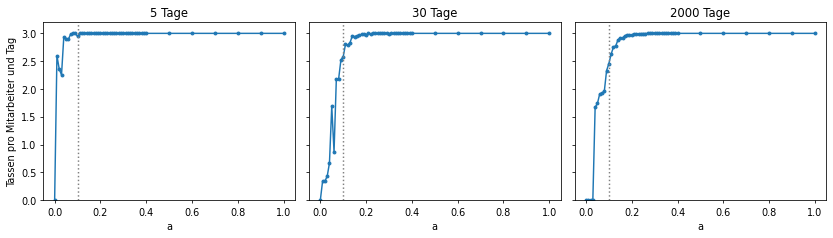

In [ ]:
import matplotlib.pyplot as plt

werte_a = [i / 100 for i in range(0, 41)] + [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

def kurve(tage):
    random.seed(2012)
    return [simuliere(a, tage)[0] for a in werte_a]

kurve5 = kurve(5)
kurve30 = kurve(30)
kurve2000 = kurve(2000)

bild_fig, bild_achsen = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for achse, werte, titel in [(bild_achsen[0], kurve5, '5 Tage'),
                            (bild_achsen[1], kurve30, '30 Tage'),
                            (bild_achsen[2], kurve2000, '2000 Tage')]:
    achse.plot(werte_a, werte, '.-')
    achse.set_title(titel)
    achse.set_xlabel('a')
    achse.set_ylim(0, 3.2)
    achse.axvline(0.1, color='gray', linestyle=':')
bild_achsen[0].set_ylabel('Tassen pro Mitarbeiter und Tag')
plt.tight_layout()
plt.show()

Der gepunktete graue Strich liegt bei `a = 0.1`, wo wir die Sprungstelle erwartet haben. Bei 5 Tagen (und noch bei 30) ist die Kurve unruhig, der Startzustand mit den vollen Kannen wirkt noch nach. Bei 2000 Tagen ist sie glatt. Hier die Zahlen der langen Läufe:

In [ ]:
for i in range(len(werte_a)):
    if werte_a[i] in [0.0, 0.03, 0.04, 0.05, 0.07, 0.08, 0.09, 0.1, 0.11, 0.12, 0.13, 0.15, 0.2, 0.25, 0.3, 1.0]:
        print('a =', werte_a[i], '-> Tassen pro Tag:', round(kurve2000[i], 2))

a = 0.0 -> Tassen pro Tag: 0.0
a = 0.03 -> Tassen pro Tag: 0.01
a = 0.04 -> Tassen pro Tag: 1.67
a = 0.05 -> Tassen pro Tag: 1.74
a = 0.07 -> Tassen pro Tag: 1.93
a = 0.08 -> Tassen pro Tag: 1.96
a = 0.09 -> Tassen pro Tag: 2.33
a = 0.1 -> Tassen pro Tag: 2.46
a = 0.11 -> Tassen pro Tag: 2.63
a = 0.12 -> Tassen pro Tag: 2.75
a = 0.13 -> Tassen pro Tag: 2.78
a = 0.15 -> Tassen pro Tag: 2.92
a = 0.2 -> Tassen pro Tag: 2.97
a = 0.25 -> Tassen pro Tag: 3.0
a = 0.3 -> Tassen pro Tag: 3.0
a = 1.0 -> Tassen pro Tag: 3.0


**Was wir sehen:**
- Für sehr kleine `a` (bis etwa 0,03) bricht der Konsum fast ganz zusammen: Wer einmal gekocht hat, ist die nächsten Tage unglücklich, und bald hat niemand mehr `n ≥ 10`.
- Von etwa 0,04 bis 0,08 pendelt er sich bei rund 2 Tassen ein (das hängt hier vom Zufall des Laufs ab, siehe Schritt 6).
- Danach steigt er stetig an und erreicht erst bei etwa `a = 0.25` die vollen **3 Tassen**.
- Es ist also **keine scharfe Sprungstelle** bei 0,1, sondern ein breiter Übergang.

## Schritt 5: Warum die volle Versorgung erst oberhalb von 1/10 gelingt

Unsere Abschätzung ging davon aus, dass jede Kanne ganz getrunken wird. Dann braucht man bei 45 Tassen am Tag 4,5 Kannen. Tatsächlich kann man nur ganze Kannen kochen, und was **abends** in der Kanne bleibt, wird weggeschüttet. Im vollen Betrieb (`a = 1`) messen wir:

In [ ]:
random.seed(5)
voll_tassen, voll_kannen, _ = simuliere(1.0, 1000)
print('Tassen pro Mitarbeiter und Tag:', voll_tassen, '| Kannen pro Tag:', voll_kannen)
je_mitarbeiter = voll_kannen / ANZAHL
print('Kannen pro Mitarbeiter und Tag:', round(je_mitarbeiter, 4), '| m/n =', round(je_mitarbeiter / voll_tassen, 4), '| 1/9 =', round(1 / 9, 4))

Tassen pro Mitarbeiter und Tag: 3.0 | Kannen pro Tag: 5.0
Kannen pro Mitarbeiter und Tag: 0.3333 | m/n = 0.1111 | 1/9 = 0.1111


Es sind **5 Kannen pro Tag**: Vormittags werden zwei gekocht (15 Personen brauchen 15 Tassen, 5 bleiben übrig), mittags reicht der Rest plus eine neue Kanne (danach ist die Kanne leer), nachmittags werden wieder zwei gekocht, und die 5 übrigen Tassen verfallen abends. Das macht `5/15 = 1/3` Kannen pro Mitarbeiter und Tag bei 3 Tassen, also `m/n = 1/9 ≈ 0,111`.

Wer immer kocht, wenn die Kanne leer ist, kommt also auf `m/n ≈ 0,111`, nicht auf `0,1`. Die Schwelle `a` muss deshalb mindestens bei `1/9` liegen, damit im Mittel alle glücklich bleiben können. Dazu kommt der Zufall: `m/n` ist nur im **Mittel** 0,111, aber nicht für jeden Mitarbeiter gleich (wer zufällig oft als Elfter in die Küche kommt, kocht öfter). Wer über der Schwelle liegt, ist unglücklich und kocht nicht, bis die Zahlen wieder passen. Deshalb muss `a` deutlich über 1/9 liegen, damit auch dann noch genug Glückliche da sind. Das passt dazu, dass die Kurve erst bei `a ≈ 0.25` die vollen 3 Tassen erreicht (bei 0,15 sind es 2,92).

## Schritt 6: Dieselbe Frage, andere Auslegung (die Hinweise)

Der Aufgabentext sagt: Ob jemand glücklich ist, entscheidet sich **morgens**. Wer morgens glücklich ist, kann deshalb am selben Tag auch zwei- oder dreimal kochen, ohne dass sich sein `m/n` zwischendurch ändert. Die Lösungshinweise rechnen anders: Sie schieben das Zehn-Tage-Fenster **nach jeder Tageszeit** weiter (30 Einträge je Mitarbeiter) und prüfen das Glück erst, wenn jemand eine leere Kanne findet. Wer vormittags gekocht hat, zählt mittags also schon als ein Mal mehr.

Wir bauen diese Variante nach, indem wir `simuliere` abwandeln: Das Fenster hat 30 Einträge (eine je Tageszeit), und `glueck` wird vor jeder Tageszeit neu berechnet.

a = 0.0 -> morgens: 0.0 | vor jeder Tageszeit: 0.0
a = 0.05 -> morgens: 1.74 | vor jeder Tageszeit: 0.01
a = 0.07 -> morgens: 1.93 | vor jeder Tageszeit: 0.02
a = 0.08 -> morgens: 1.96 | vor jeder Tageszeit: 0.4
a = 0.09 -> morgens: 2.33 | vor jeder Tageszeit: 1.77
a = 0.1 -> morgens: 2.46 | vor jeder Tageszeit: 2.38
a = 0.12 -> morgens: 2.75 | vor jeder Tageszeit: 2.75
a = 0.15 -> morgens: 2.92 | vor jeder Tageszeit: 2.92
a = 0.2 -> morgens: 2.97 | vor jeder Tageszeit: 2.97
a = 0.3 -> morgens: 3.0 | vor jeder Tageszeit: 3.0


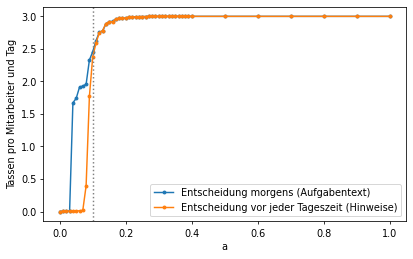

In [ ]:
def simuliere_fein(a, tage):
    fenster_tassen = [[1] * 30 for m in range(ANZAHL)]     # Tassen je Tageszeit, letzte 30 Tageszeiten
    fenster_kochen = [[0] * 30 for m in range(ANZAHL)]
    summe_tassen = 0
    for tag in range(tage):
        kanne = 0
        for zeit in range(3):
            glueck = []
            for m in range(ANZAHL):
                n = sum(fenster_tassen[m])
                k = sum(fenster_kochen[m])
                glueck.append(n >= 10 and k / n < a)
            tassen = [0] * ANZAHL
            gekocht = [0] * ANZAHL
            kanne = tageszeit(glueck, kanne, tassen, gekocht)
            for m in range(ANZAHL):
                fenster_tassen[m].pop(0)
                fenster_tassen[m].append(tassen[m])
                fenster_kochen[m].pop(0)
                fenster_kochen[m].append(gekocht[m])
            summe_tassen = summe_tassen + sum(tassen)
    return summe_tassen / (ANZAHL * tage)

random.seed(2012)
kurve2000_fein = [simuliere_fein(a, 2000) for a in werte_a]

bild_fig, bild_achse = plt.subplots(figsize=(6, 3.8))
bild_achse.plot(werte_a, kurve2000, '.-', label='Entscheidung morgens (Aufgabentext)')
bild_achse.plot(werte_a, kurve2000_fein, '.-', label='Entscheidung vor jeder Tageszeit (Hinweise)')
bild_achse.axvline(0.1, color='gray', linestyle=':')
bild_achse.set_xlabel('a')
bild_achse.set_ylabel('Tassen pro Mitarbeiter und Tag')
bild_achse.legend()
plt.tight_layout()
plt.show()

for i in range(len(werte_a)):
    if werte_a[i] in [0.0, 0.05, 0.07, 0.08, 0.09, 0.1, 0.12, 0.15, 0.2, 0.3]:
        print('a =', werte_a[i], '-> morgens:', round(kurve2000[i], 2), '| vor jeder Tageszeit:', round(kurve2000_fein[i], 2))

Die Kurve der Hinweise (orange) ist **näher an der erwarteten Sprungfunktion**: Bis 0,07 bricht der Konsum zusammen (die Hinweise sehen den Beginn bei etwa 0,08), dann steigt er schnell an und erreicht bei etwa `a = 0.2` fast die 3 Tassen. Die Kurve nach dem Aufgabentext (blau) hat für kleine `a` einen Zwischenbereich bei rund 2 Tassen, der bei der Hinweis-Variante fehlt, und liegt bei 0,09 und 0,1 höher; ab 0,12 sind beide praktisch gleich. Beide haben denselben groben Charakter: kleine `a` bedeuten Zusammenbruch, große `a` volle Versorgung, dazwischen ein Übergang.

**Warum der Unterschied?** Bei der morgendlichen Entscheidung darf ein Glücklicher am selben Tag bis zu dreimal kochen, ohne dass sich sein Kochanteil ändert. So stehen an einem Tag mit Glücklichen mehr Kannen zur Verfügung, und das hält den Konsum bei kleinem `a` am Leben (aber nur wenn der Lauf Glück hat, siehe unten). Bei der feineren Prüfung wird jemand, der vormittags gekocht hat, sofort „teurer“, und der Kreislauf bricht eher zusammen.

**Wie zufällig ist das?** Bei kleinen `a` entscheidet der Zufall, ob der Konsum zusammenbricht oder sich stabilisiert. Wir vergleichen drei Läufe (verschiedene Zufallszahlen) für beide Varianten:

In [ ]:
for a in [0.03, 0.05, 0.08]:
    morgens = []
    fein = []
    for lauf in [1, 2, 3]:
        random.seed(lauf)
        morgens.append(round(simuliere(a, 2000)[0], 2))
        random.seed(lauf)
        fein.append(round(simuliere_fein(a, 2000), 2))
    print('a =', a, '| morgens:', morgens, '| vor jeder Tageszeit:', fein)

a = 0.03 | morgens: [0.01, 0.01, 0.01] | vor jeder Tageszeit: [0.0, 0.0, 0.0]
a = 0.05 | morgens: [0.03, 1.75, 1.74] | vor jeder Tageszeit: [0.01, 0.01, 0.01]
a = 0.08 | morgens: [1.96, 1.96, 1.96] | vor jeder Tageszeit: [1.59, 1.69, 1.69]


Bei `a = 0.05` bricht der Konsum nach dem Aufgabentext in einem von drei Läufen zusammen (0,03), in den beiden anderen pendelt er sich bei etwa 1,7 ein; bei `a = 0.03` bricht er immer zusammen, bei `a = 0.08` stabilisiert er sich immer bei knapp 2. Die Hinweis-Variante bricht bei `a = 0.05` immer zusammen. Eine einzelne Kurve im Zwischenbereich ist also mit Vorsicht zu lesen; im Zwischenbereich müsste man mehrere Läufe mitteln.

## Schritt 7: War das Ergebnis erwartet?

- **Das Grundmuster stimmt:** Kleine `a` führen zum Zusammenbruch des Kaffeekonsums, große `a` zur vollen Versorgung mit 3 Tassen pro Tag.
- **Kein scharfer Sprung:** Der Übergang ist breit (je nach Auslegung zwischen etwa 0,04 oder 0,08 und 0,25). Dass er nicht scharf ist, liegt am Zufall: `m/n` schwankt von Person zu Person, und die Glücklichen müssen die Kannen für die Unglücklichen mitkochen.
- **Lage der Stufe:** Die Abschätzung `1/10` ist zu klein, weil Kannen nicht voll genutzt werden (5 statt 4,5 Kannen am Tag, `1/9`) und weil die Schwankungen Reserve brauchen. Die Hinweise sehen den Beginn des Konsums bei etwa 0,08 und das Maximum bei etwa 0,2; unsere Hinweis-Variante liefert das ebenfalls.
- **Zwei Auslegungen, zwei Kurven:** Auch kleine Unterschiede im Modell (wann wird das Glück geprüft?) verschieben die Kurve spürbar. Eine Simulation ist so gut wie das Modell, das man in sie einbaut. Deshalb sollte man im Bericht die Annahmen offen nennen.

## Zum Schluss: Warum kein MiniZinc?

MiniZinc löst Aufgaben mit Entscheidungsvariablen und Bedingungen, in denen eine zulässige oder beste Belegung gesucht wird. Die Kaffeerunde ist eine **Zufallssimulation**: Es gibt nichts zu optimieren, wir wollen den Mittelwert vieler zufälliger Abläufe kennen. Man könnte zu einer festen Reihenfolge der Mitarbeiter den Ablauf in MiniZinc nachrechnen, aber das wäre nur eine Umschreibung der Simulation und brächte kein neues Ergebnis. Es gibt außerdem keine Beispieldaten, an denen man Laufzeiten messen könnte. Deshalb haben wir hier bewusst kein MiniZinc-Modell aufgenommen.